In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Data Understanding

In [3]:
df.shape

(20640, 10)

In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [6]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

## 2. EDA

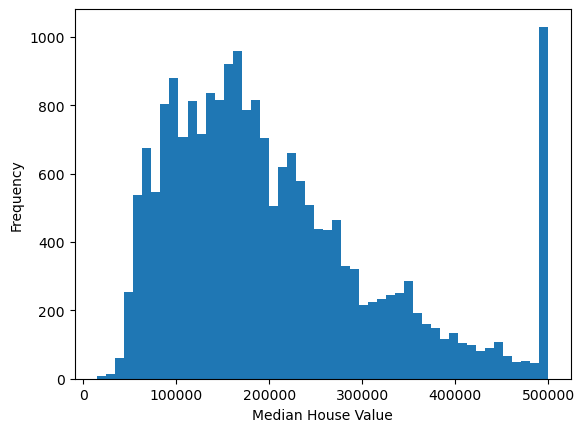

In [9]:
plt.hist(df['median_house_value'], bins=50)
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

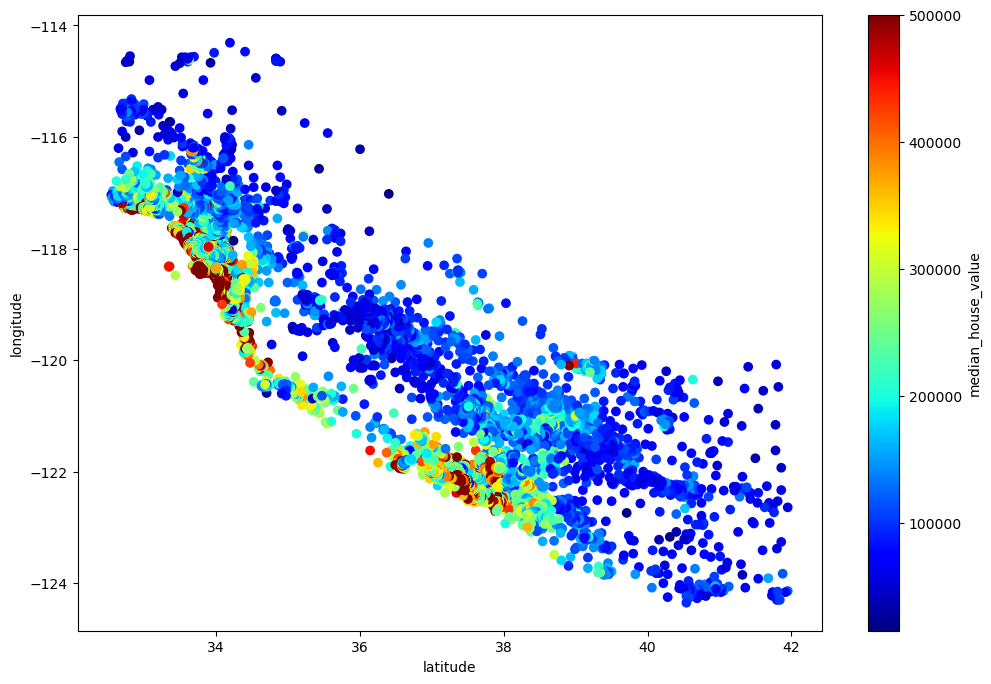

In [14]:
plt.figure(figsize=(12,8))
plt.scatter(df['latitude'], df['longitude'], c=df['median_house_value'], cmap='jet')
plt.colorbar(label='median_house_value')
plt.xlabel('latitude')
plt.ylabel('longitude')
plt.show()

## 3. Train-Test Split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('median_house_value', axis= 1),
                                                    df['median_house_value'],
                                                    test_size= 0.2,
                                                    random_state= 42)

## 4. Missing Value Handling

In [18]:
mean_bedrooms = X_train['total_bedrooms'].mean()

X_train['total_bedrooms'] = X_train['total_bedrooms'].fillna(mean_bedrooms)
X_test['total_bedrooms'] = X_test['total_bedrooms'].fillna(mean_bedrooms)

## 5. Categorical Encoding


In [19]:
encoder = OneHotEncoder(sparse_output=False, drop=['ISLAND'])

X_train_encoded = encoder.fit_transform(X_train[['ocean_proximity']])
X_test_encoded = encoder.transform(X_test[['ocean_proximity']])

In [20]:
X_train_num = X_train.drop('ocean_proximity', axis=1)
X_test_num = X_test.drop('ocean_proximity', axis=1)

In [21]:
X_train_final = np.concatenate([X_train_num, X_train_encoded], axis=1)
X_test_final = np.concatenate([X_test_num, X_test_encoded], axis=1)

In [22]:
X_train_final

array([[-117.03,   32.71,   33.  , ...,    0.  ,    0.  ,    1.  ],
       [-118.16,   33.77,   49.  , ...,    0.  ,    0.  ,    1.  ],
       [-120.48,   34.66,    4.  , ...,    0.  ,    0.  ,    1.  ],
       ...,
       [-118.38,   34.03,   36.  , ...,    0.  ,    0.  ,    0.  ],
       [-121.96,   37.58,   15.  , ...,    0.  ,    0.  ,    0.  ],
       [-122.42,   37.77,   52.  , ...,    0.  ,    1.  ,    0.  ]],
      shape=(16512, 12))

## 6. Feature Scaling


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [24]:
X_train_scaled

array([[ 1.27258656, -1.3728112 ,  0.34849025, ..., -0.68057418,
        -0.35564565,  2.62975816],
       [ 0.70916212, -0.87669601,  1.61811813, ..., -0.68057418,
        -0.35564565,  2.62975816],
       [-0.44760309, -0.46014647, -1.95271028, ..., -0.68057418,
        -0.35564565,  2.62975816],
       ...,
       [ 0.59946887, -0.75500738,  0.58654547, ..., -0.68057418,
        -0.35564565, -0.3802631 ],
       [-1.18553953,  0.90651045, -1.07984112, ..., -0.68057418,
        -0.35564565, -0.3802631 ],
       [-1.41489815,  0.99543676,  1.85617335, ..., -0.68057418,
         2.81178749, -0.3802631 ]], shape=(16512, 12))

## 7. Baseline Models

In [25]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)

In [26]:
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
r2_lr = r2_score(y_test, y_pred)

print("RMSE:", rmse_lr)
print("R2:", r2_lr)

RMSE: 70031.4878994794
R2: 0.6257344555133744


In [27]:
dtree = DecisionTreeRegressor()
dtree.fit(X_train_scaled, y_train)
y_pred = dtree.predict(X_test_scaled)

In [28]:
rmse_dtree = np.sqrt(mean_squared_error(y_test, y_pred))
r2_dtree = r2_score(y_test, y_pred)

print("RMSE:", rmse_dtree)
print("R2:", r2_dtree)

RMSE: 70162.99351375544
R2: 0.6243275389169156


In [29]:
gb = GradientBoostingRegressor()
gb.fit(X_train_scaled, y_train)
y_pred = gb.predict(X_test_scaled)

In [30]:
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_gb = r2_score(y_test, y_pred)

print("RMSE:", rmse_gb)
print("R2:", r2_gb)

RMSE: 55970.256414721516
R2: 0.760939549778193


In [31]:
rf = RandomForestRegressor()
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)

In [32]:
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred))
r2_rf = r2_score(y_test, y_pred)

print("RMSE:", rmse_rf)
print("R2:", r2_rf)

RMSE: 48929.63273494958
R2: 0.8173006290913152


In [35]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Gradient Boosting', 'Random Forest'],
    'RMSE': [rmse_lr, rmse_dtree, rmse_gb, rmse_rf],
    'R2': [r2_lr, r2_dtree, r2_gb, r2_rf]
})

results

,Model,RMSE,R2
0,Linear Regression,70031.487899,0.625734
1,Decision Tree,70162.993514,0.624328
2,Gradient Boosting,55970.256415,0.760940
3,Random Forest,48929.632735,0.817301


In [40]:
xgb = XGBRegressor()
xgb.fit(X_train_scaled, y_train)
y_pred = xgb.predict(X_test_scaled)

In [41]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_xgb = r2_score(y_test, y_pred)

print("RMSE:", rmse_xgb)
print("R2:", r2_xgb)

RMSE: 47775.6462815244
R2: 0.8258167934196091


## 8. Advanced Model

In [42]:
para_grid = {
    'n_estimators': [100,200,250],
    'learning_rate' : [0.05, 0.1, 0.3],
    'max_depth' : [3, 5, 10],
    'min_child_weight' : [1, 3],
    'subsample': [0.8, 1],
    'colsample_bytree' :[0.8, 1]
}

In [43]:
from sklearn.model_selection import GridSearchCV
cv = GridSearchCV(XGBRegressor(), param_grid= para_grid, cv=5, n_jobs= -1)

In [44]:
cv.fit(X_train_scaled, y_train)

C:\Users\visha\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
1 fits failed out of a total of 1080.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\visha\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\visha\anaconda3\Lib\site-packages\xgboost\core.py", line 569, in inner_f
    return func(**kwargs)
  File "C:\Users\visha\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 1405, in fit
    train_dmatrix, evals = _wrap_evaluation_matrices(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1], 'learning_rate': [0.05, 0.1, ...], 'max_depth': [3, 5, ...], 'min_child_weight': [1, 3], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ver

In [45]:
cv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.05,
 'max_depth': 10,
 'min_child_weight': 3,
 'n_estimators': 250,
 'subsample': 0.8}

In [46]:
cv.best_score_

np.float64(0.8442401333562909)

In [57]:
xgb = XGBRegressor(colsample_bytree= 0.8, 
                   learning_rate= 0.05, 
                   max_depth=10, 
                   min_child_weight= 3, 
                   n_estimators= 250,
                   subsample= 0.8
                  )
xgb.fit(X_train_final, y_train)
y_pred = xgb.predict(X_test_final)

In [58]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_xgb = r2_score(y_test, y_pred)

print("RMSE:", rmse_xgb)
print("R2:", r2_xgb)

RMSE: 45043.540997304655
R2: 0.8451689038105112


## 10. Feature Importance + Final Results

In [50]:
importance = xgb.feature_importances_

feature_names = list(X_train_num.columns) + list(encoder.get_feature_names_out())
feature_importance = pd.DataFrame({'Feature': feature_names,'Importance': importance}).sort_values('Importance', ascending=False)

feature_importance

,Feature,Importance
9,ocean_proximity_INLAND,0.566030
7,median_income,0.115351
10,ocean_proximity_NEAR BAY,0.082758
11,ocean_proximity_NEAR OCEAN,0.072251
8,ocean_proximity_<1H OCEAN,0.044506
0,longitude,0.029286
1,latitude,0.029136
2,housing_median_age,0.015173
5,population,0.014594
3,total_rooms,0.011201


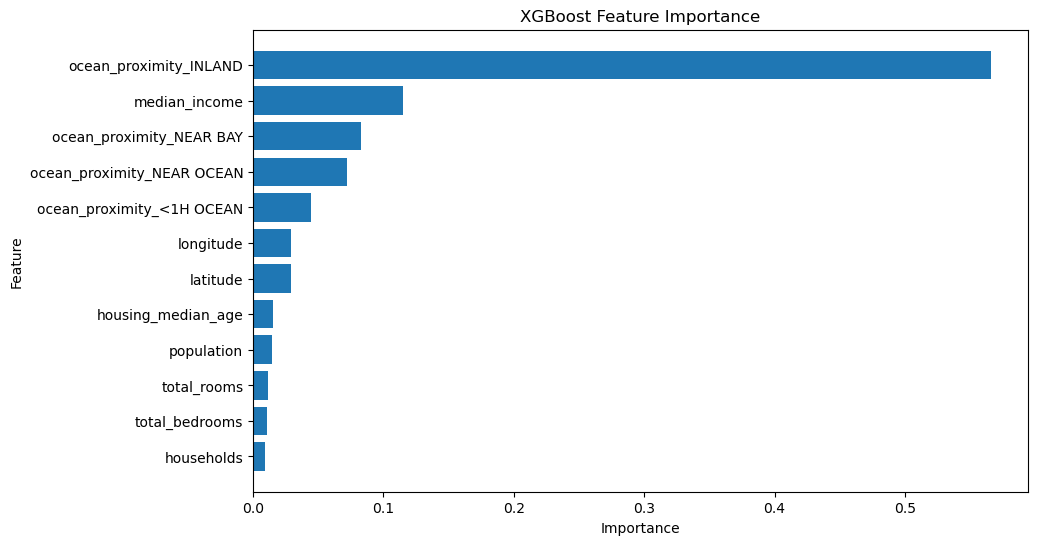

In [51]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance')

plt.gca().invert_yaxis()

plt.show()

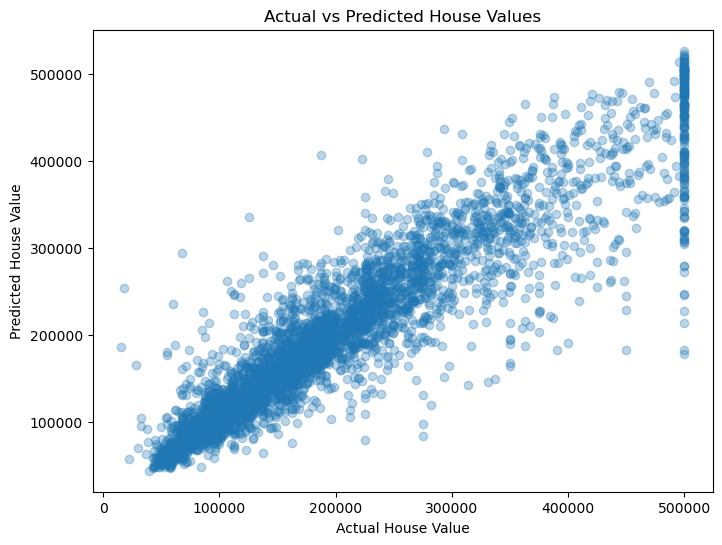

In [52]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Actual vs Predicted House Values')

plt.show()

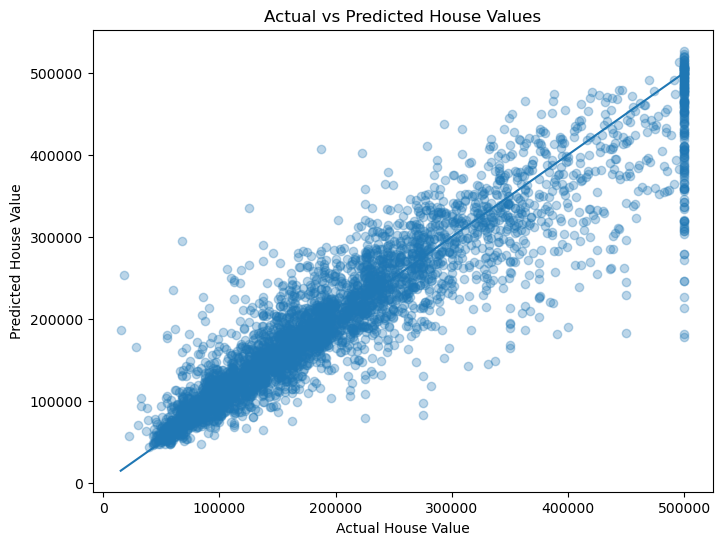

In [53]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Actual vs Predicted House Values')

plt.show()

In [55]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost'
    ],
    'RMSE': [
        rmse_lr,
        rmse_dtree,
        rmse_rf,
        rmse_gb,
        rmse_xgb
    ],
    'R2': [
        r2_lr,
        r2_dtree,
        r2_rf,
        r2_gb,
        r2_xgb
    ]
})

results.sort_values('R2', ascending=False)

,Model,RMSE,R2
4,XGBoost,45043.540997,0.845169
2,Random Forest,48929.632735,0.817301
3,Gradient Boosting,55970.256415,0.760940
0,Linear Regression,70031.487899,0.625734
1,Decision Tree,70162.993514,0.624328


In [61]:
cv_score= np.mean(cross_val_score(xgb, X_train_final, y_train, cv=5, scoring= 'r2'))

In [62]:
final_results = {
    'Model': 'Tuned XGBoost',
    'RMSE': rmse_xgb,
    'Test R2': r2_xgb,
    'CV R2': cv_score
}

final_results

{'Model': 'Tuned XGBoost',
 'RMSE': np.float64(45043.540997304655),
 'Test R2': 0.8451689038105112,
 'CV R2': np.float64(0.8445816163664664)}

In [63]:
import joblib

joblib.dump(xgb, 'house_price_xgb_model.pkl')

['house_price_xgb_model.pkl']

In [64]:
joblib.load('house_price_xgb_model.pkl')

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None
